# Capitolo 2 — Filtri, convoluzione e scale
Arcangelo Distante e Cosimo Distante — **Computer Vision**

Questo notebook usa esclusivamente segnali, punti e camere sintetici, definiti nel codice. Non contiene immagini esterne, benchmark, addestramento o misure di una camera reale. Le quantità calcolate illustrano i modelli e le loro condizioni di validità.

## Avvio e materiali
In Google Colab aprire questo file, selezionare un runtime **CPU** e avviare le celle dall’alto. Non servono GPU, file da caricare né download di dati. Sono necessarie NumPy e Matplotlib, normalmente già disponibili in Colab; in un ambiente nuovo installarle prima dell’esecuzione con `%pip install numpy matplotlib`. In locale è adeguato Python 3 con le stesse dipendenze.

La cartella `output_capitolo02` viene creata nello stesso runtime. Alla fine contiene figure, eventuali CSV e `metriche.json`. Per conservarla in Colab scaricarla dal pannello File prima di chiudere il runtime, oppure copiarla nel proprio Drive dopo averlo montato. Il riavvio elimina le variabili: rieseguire dalla prima cella. Per ogni esperimento modificato conservare parametri, seed e output in una nuova cartella.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT = Path('output_capitolo02')
OUTPUT.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
metriche = {}
plt.rcParams.update({'font.size': 10, 'figure.figsize': (7, 4)})

def salva_figura(nome):
    plt.tight_layout()
    plt.savefig(OUTPUT / (nome + '.png'), dpi=160)
    plt.show()
    plt.close()

def proietta(P, X):
    q = np.c_[X, np.ones(len(X))] @ P.T
    return q[:, :2] / q[:, 2:]


## N2.A1 — Convoluzione, correlazione e bordo

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

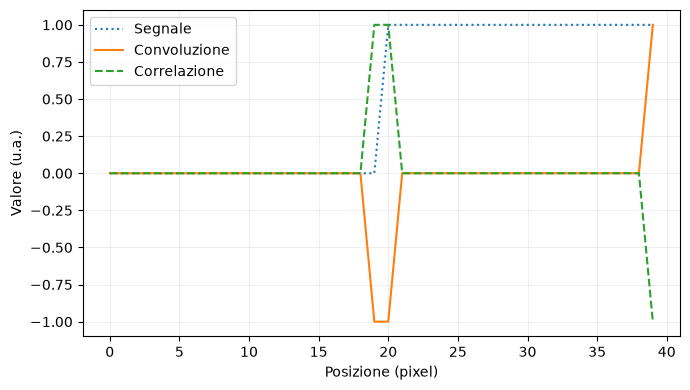

In [2]:
segnale = np.r_[np.zeros(20), np.ones(20)]
h = np.array([-1., 0, 1.])
conv = np.convolve(segnale, h, mode='same')
corr = np.correlate(segnale, h, mode='same')
metriche['errore_antisimmetria_interno'] = float(np.max(np.abs(conv[1:-1]+corr[1:-1])))
plt.plot(segnale, ':', label='Segnale')
plt.plot(conv, label='Convoluzione')
plt.plot(corr, '--', label='Correlazione')
plt.xlabel('Posizione (pixel)'); plt.ylabel('Valore (u.a.)')
plt.legend(); plt.grid(alpha=0.2)
salva_figura('A1_convoluzione')


**Domande**

1. Spiegare il segno delle risposte al gradino.
2. Ripetere il confronto con un kernel simmetrico e separare gli effetti del bordo.

## N2.A2 — Media, mediana e impulso

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

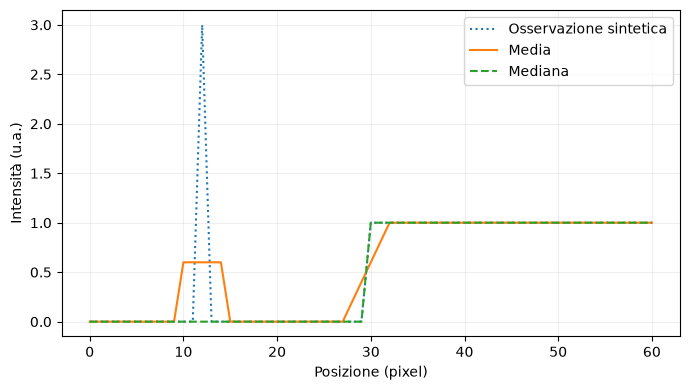

In [3]:
x = np.arange(61)
ideale = (x >= 30).astype(float)
osservato = ideale.copy(); osservato[12] = 3.
padded = np.pad(osservato, 2, mode='edge')
medio = np.convolve(padded, np.ones(5)/5, mode='valid')
mediano = np.array([np.median(padded[i:i+5]) for i in range(len(x))])
metriche['errore_L1_media'] = float(np.abs(medio-ideale).sum())
metriche['errore_L1_mediana'] = float(np.abs(mediano-ideale).sum())
plt.plot(x, osservato, ':', label='Osservazione sintetica')
plt.plot(x, medio, label='Media')
plt.plot(x, mediano, '--', label='Mediana')
plt.xlabel('Posizione (pixel)'); plt.ylabel('Intensità (u.a.)')
plt.legend(); plt.grid(alpha=0.2)
salva_figura('A2_impulso')


**Domande**

1. Interpretare i due errori rispetto al segnale ideale dichiarato.
2. Proporre una struttura sottile per cui la mediana possa eliminare informazione utile.

## N2.A3 — Decimazione e residuo multiscala

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

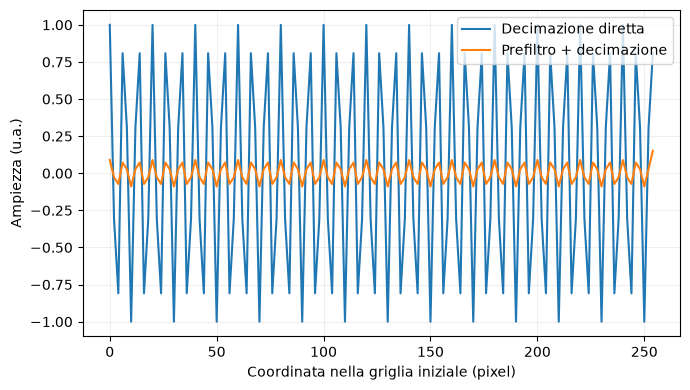

Errore di ricostruzione con residuo: 1.1102230246251565e-16


In [4]:
n = np.arange(256)
segnale = np.cos(2*np.pi*0.35*n)
assi = np.arange(-6, 7)
g = np.exp(-assi**2/2); g /= g.sum()
filtrato = np.convolve(np.pad(segnale, 6, mode='reflect'), g, mode='valid')
diretto = segnale[::2]
ridotto = filtrato[::2]
# Espansione lineare definita esplicitamente: stessa operazione nei due versi.
espanso = np.interp(n, n[::2], ridotto)
residuo = segnale - espanso
ricostruito = residuo + espanso
metriche['errore_ricostruzione'] = float(np.max(np.abs(ricostruito-segnale)))
plt.plot(n[::2], diretto, label='Decimazione diretta')
plt.plot(n[::2], ridotto, label='Prefiltro + decimazione')
plt.xlabel('Coordinata nella griglia iniziale (pixel)')
plt.ylabel('Ampiezza (u.a.)'); plt.legend(); plt.grid(alpha=0.2)
salva_figura('A3_decimazione')
print('Errore di ricostruzione con residuo:', metriche['errore_ricostruzione'])


**Domande**

1. Perché la frequenza di partenza richiede filtraggio prima del dimezzamento?
2. Spiegare il ruolo del residuo nella ricostruzione e che cosa accade se viene scartato.

## Conservare i risultati

La cella seguente salva le quantità calcolate durante questa esecuzione. I valori del file descrivono questi dati sintetici e questi parametri. Non rappresentano prestazioni su dati reali.

In [5]:
with (OUTPUT / 'metriche.json').open('w') as f_json:
    json.dump(metriche, f_json, indent=2, allow_nan=False)
print('Output salvati in:', OUTPUT)

Output salvati in: output_capitolo02
